# Obesity Drug Pipeline: Competitive Intelligence

**Question:** Who will be competing in the US obesity market by 2030, with what
mechanisms, and when do the key readouts land?

**Data:** every interventional obesity or overweight trial registered on
ClinicalTrials.gov that started in 2015 or later, plus FDA approval records.

**Method:**
1. Map free-text trial interventions to named molecules and mechanisms (`molecules.py`).
2. Find each molecule's most advanced phase and its Phase 3 primary completion dates.
3. Apply historical phase-success rates to estimate how many new entrants to expect each year.

Terms: a **Phase 3** trial is the large confirmatory study a sponsor files on.
**Primary completion** is the date the last patient gives data for the main
endpoint, so it is the earliest point a topline readout can come.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd() if Path.cwd().name.startswith("04-") else Path("04-obesity-pipeline-intelligence")
sys.path.insert(0, str(HERE.parent))
sys.path.insert(0, str(HERE))
from common import style  # noqa: E402
from molecules import classify, APPROVED_US_OBESITY, APPROVED_US_OTHER  # noqa: E402

style.apply()
RAW, FIG, TAB = HERE / "data" / "raw", HERE / "outputs" / "figures", HERE / "outputs" / "tables"
TAB.mkdir(parents=True, exist_ok=True)
SRC = "ClinicalTrials.gov API v2, trials starting 2015 or later"

trials = pd.read_csv(RAW / "trials.csv.gz")
ivs = pd.read_csv(RAW / "interventions.csv.gz")
print(f"{len(trials):,} interventional trials, {len(ivs):,} intervention records")
trials.head(3)

8,309 interventional trials, 16,657 intervention records


,nct_id,title,acronym,sponsor,sponsor_class,collaborators,phases,allocation,primary_purpose,enrollment,overall_status,start_date,primary_completion_date,primary_completion_type,completion_date,conditions,countries,has_results
0,NCT04251156,Research Study of How Well Semaglutide Works i...,STEP7,Novo Nordisk A/S,INDUSTRY,NaN,PHASE3,RANDOMIZED,TREATMENT,375,COMPLETED,2020-12-08,2022-08-23,ACTUAL,2022-08-23,"Overweight|Obesity|Diabetes Mellitus, Type 2",Brazil|China|Hong Kong|South Korea,True
1,NCT03919929,Treating PCOS With Semaglutide vs Active Lifes...,TEAL,"University of Colorado, Denver",OTHER,National Institute of Diabetes and Digestive a...,PHASE2|PHASE3,RANDOMIZED,TREATMENT,60,COMPLETED,2019-05-03,2023-10-03,ACTUAL,2023-10-03,PCOS|Adolescent Obesity|NAFLD,United States,True
2,NCT07521631,Efficacy and Safety of HDM1005 Compared to Tir...,NaN,"Hangzhou Zhongmei Huadong Pharmaceutical Co., ...",INDUSTRY,NaN,PHASE2,RANDOMIZED,TREATMENT,372,RECRUITING,2026-03-31,2027-02-04,ESTIMATED,2027-07-23,Obesity,China,False


## 1. Map interventions to molecules

Only drug and biologic interventions are kept. Each intervention's name, other
names and description are searched for known molecule names and code numbers.

In [2]:
drug_ivs = ivs[ivs["type"].isin(["DRUG", "BIOLOGICAL", "COMBINATION_PRODUCT"])].copy()
drug_ivs["text"] = drug_ivs[["name", "other_names"]].fillna("").agg(" ".join, axis=1)

rows = []
for r in drug_ivs.itertuples():
    for mol, sponsor, mech in classify(r.text):
        rows.append({"nct_id": r.nct_id, "molecule": mol, "mol_sponsor": sponsor, "mechanism": mech})
hits = pd.DataFrame(rows).drop_duplicates()
# Molecules found only through their INN stem take the trial's lead sponsor
hits = hits.merge(trials[["nct_id", "sponsor"]], on="nct_id", how="left")
hits["mol_sponsor"] = np.where(hits["mol_sponsor"] == "unlisted", hits["sponsor"], hits["mol_sponsor"])
hits = hits.drop(columns="sponsor").drop_duplicates()

trials["start"] = pd.to_datetime(trials["start_date"], errors="coerce")
trials["pcd"] = pd.to_datetime(trials["primary_completion_date"], errors="coerce")
trials["start_year"] = trials["start"].dt.year
trials["phase"] = (trials["phases"].fillna("")
                   .str.replace("EARLY_PHASE1", "PHASE1")
                   .str.split("|").apply(lambda ps: max([p for p in ps if p] or ["NA"])))

m = hits.merge(trials, on="nct_id")
matched_share = drug_ivs["nct_id"].isin(hits["nct_id"]).groupby(drug_ivs["nct_id"]).any().mean()
print(f"{hits['nct_id'].nunique():,} trials matched to a named molecule "
      f"({matched_share:.0%} of trials that test a drug)")

916 trials matched to a named molecule (42% of trials that test a drug)


Unmatched drug interventions in **industry** trials are listed so nothing important is silently dropped.

In [3]:
ind = trials.loc[trials["sponsor_class"] == "INDUSTRY", "nct_id"]
unmatched = (drug_ivs[drug_ivs["nct_id"].isin(ind) & ~drug_ivs["nct_id"].isin(hits["nct_id"])]
             .groupby("name").size().sort_values(ascending=False))
unmatched.head(25)

name
Placebo                         219
ZT006                            14
placebo                           9
PF-06865571                       7
DA-302168S                        7
NGM395                            6
RAY1225                           6
MWN109 2                          6
MWN109 1                          6
LIK066                            6
DCCR                              5
HSG4112                           5
MWN109 3                          5
ARD-101                           5
SHR-1179 ; Placebo                5
NNC0662-0419                      4
NNC0519-0130                      4
MDR-001                           4
Metformin                         4
BI 3034701                        4
BGM1812                           4
VCT220                            4
HDM1005 injection or placebo      4
Placebo of DA-302168S             4
ABBV-295                          4
dtype: int64

## 2. Industry investment has shifted from single GLP-1 agonists to next-generation mechanisms

Industry-sponsored trial starts per year, by mechanism. One trial can test more
than one mechanism (for example a head-to-head study), so it can count twice.

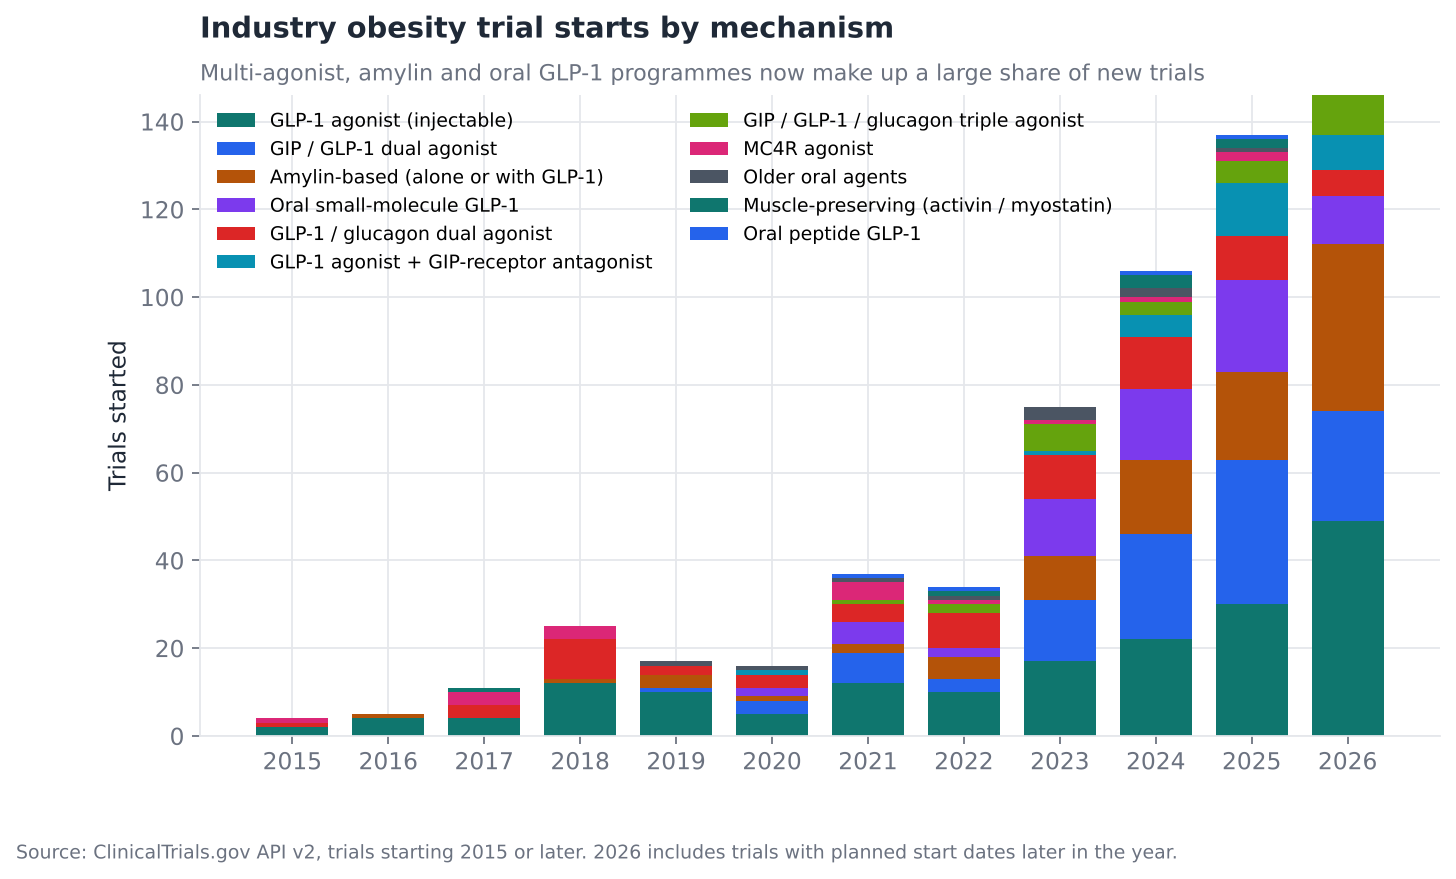

mechanism,GLP-1 agonist (injectable),GIP / GLP-1 dual agonist,Amylin-based (alone or with GLP-1),Oral small-molecule GLP-1,GLP-1 / glucagon dual agonist,GLP-1 agonist + GIP-receptor antagonist,GIP / GLP-1 / glucagon triple agonist,MC4R agonist,Older oral agents,Muscle-preserving (activin / myostatin),Oral peptide GLP-1
start_year,,,,,,,,,,,
2015.0,2,0,0,0,1,0,0,1,0,0,0
2016.0,4,0,1,0,0,0,0,0,0,0,0
2017.0,4,0,0,0,3,0,0,3,0,1,0
2018.0,12,0,1,0,9,0,0,3,0,0,0
2019.0,10,1,3,0,2,0,0,0,1,0,0
2020.0,5,3,1,2,3,1,0,0,1,0,0
2021.0,12,7,2,5,4,0,1,4,1,0,1
2022.0,10,3,5,2,8,0,2,1,1,1,1
2023.0,17,14,10,13,10,1,6,1,3,0,0


In [4]:
ind_m = m[m["sponsor_class"] == "INDUSTRY"]
by_year = (ind_m[(ind_m["start_year"] >= 2015) & (ind_m["start_year"] <= ind_m["start_year"].max())]
           .drop_duplicates(["nct_id", "mechanism"])
           .pivot_table(index="start_year", columns="mechanism", values="nct_id", aggfunc="count", fill_value=0))
order = by_year.sum().sort_values(ascending=False).index
by_year = by_year[order]

fig, ax = plt.subplots(figsize=(10, 5.2))
bottom = np.zeros(len(by_year))
for i, col in enumerate(by_year.columns):
    ax.bar(by_year.index, by_year[col], bottom=bottom, label=col, color=style.PALETTE[i % len(style.PALETTE)], width=0.75)
    bottom += by_year[col].values
ax.set_title("Industry obesity trial starts by mechanism")
style.subtitle(ax, "Multi-agonist, amylin and oral GLP-1 programmes now make up a large share of new trials")
ax.set_ylabel("Trials started")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
ax.set_xticks(by_year.index)
ax.tick_params(axis="x", rotation=0)
style.source(fig, SRC + f". {int(by_year.index.max())} includes trials with planned start dates later in the year.")
style.save(fig, FIG / "01_trial_starts_by_mechanism.png")
by_year

## 3. The pipeline: most advanced phase for every named molecule

Industry-sponsored trials only, so academic studies of approved drugs do not
inflate the pipeline. A molecule counts as **US-relevant** if at least one of
its Phase 2 or 3 trials has a US site; the rest are **China-first** or
ex-US programmes, which matter as licensing targets rather than near-term
US competitors.

In [5]:
PHASE_RANK = {"PHASE1": 1, "PHASE2": 2, "PHASE3": 3, "PHASE4": 4}
live = m[~m["overall_status"].isin(["WITHDRAWN"]) & (m["sponsor_class"] == "INDUSTRY")].copy()
live["phase_rank"] = live["phase"].map(PHASE_RANK).fillna(0)
live["us_site"] = live["countries"].fillna("").str.contains("United States")
live["cn_site"] = live["countries"].fillna("").str.contains("China")
# Not-yet-recruiting trials sometimes lack a completion date: assume 24 months after start
live["pcd_est"] = live["pcd"].fillna(live["start"] + pd.DateOffset(months=24))

def ph3(s):
    return live.loc[s.index, "phase_rank"] == 3

pipe = (live.groupby(["molecule", "mol_sponsor", "mechanism"])
            .agg(max_phase=("phase_rank", "max"),
                 trials=("nct_id", "nunique"),
                 ph3_trials=("phase_rank", lambda s: int((s == 3).sum())),
                 ph3_enrolment=("enrollment", lambda s: int(s[ph3(s)].sum())),
                 last_ph3_pcd=("pcd_est", lambda s: s[ph3(s)].max()),
                 us_relevant=("us_site", lambda s: bool(s[live.loc[s.index, "phase_rank"] >= 2].any())),
                 us_max_phase=("phase_rank", lambda s: s[live.loc[s.index, "us_site"]].max() if live.loc[s.index, "us_site"].any() else 0),
                 last_us_ph3_pcd=("pcd_est", lambda s: s[ph3(s) & live.loc[s.index, "us_site"]].max()),
                 china_trials=("cn_site", "sum"))
            .reset_index())
pipe["status"] = np.select(
    [pipe["molecule"].isin(APPROVED_US_OBESITY), pipe["molecule"].isin(APPROVED_US_OTHER),
     pipe["mol_sponsor"].str.contains("discontinued")],
    ["Approved (US obesity)", "Approved (US diabetes only)", "Discontinued"], "In development")
pipe = pipe.sort_values(["status", "max_phase", "ph3_enrolment"], ascending=[True, False, False])
pipe.to_csv(TAB / "pipeline_by_molecule.csv", index=False)
dev = pipe[pipe["status"] == "In development"]
print(f"In development: {len(dev)} molecules; {int((dev['max_phase'] == 3).sum())} in Phase 3 somewhere, "
      f"{int((dev['us_max_phase'] == 3).sum())} in Phase 3 with US sites")
pipe

In development: 31 molecules; 22 in Phase 3 somewhere, 14 in Phase 3 with US sites


,molecule,mol_sponsor,mechanism,max_phase,trials,ph3_trials,ph3_enrolment,last_ph3_pcd,us_relevant,us_max_phase,last_us_ph3_pcd,china_trials,status
21,dulaglutide,Eli Lilly,GLP-1 agonist (injectable),4.0,1,0,0,NaT,False,0.0,NaT,0,Approved (US diabetes only)
28,lixisenatide,Sanofi,GLP-1 agonist (injectable),2.0,1,0,0,NaT,False,0.0,NaT,0,Approved (US diabetes only)
26,exenatide,AstraZeneca,GLP-1 agonist (injectable),1.0,1,0,0,NaT,False,0.0,NaT,0,Approved (US diabetes only)
41,semaglutide (inj.),Novo Nordisk,GLP-1 agonist (injectable),4.0,112,52,51057,2030-03-20,True,4.0,2030-03-20,18,Approved (US obesity)
44,tirzepatide,Eli Lilly,GIP / GLP-1 dual agonist,4.0,63,26,34185,2028-09-25,True,4.0,2028-09-25,11,Approved (US obesity)
27,liraglutide,Novo Nordisk,GLP-1 agonist (injectable),4.0,22,6,1401,2023-08-01,True,4.0,2023-08-01,0,Approved (US obesity)
36,orlistat,various,Older oral agents,4.0,6,1,638,NaT,True,4.0,NaT,0,Approved (US obesity)
32,naltrexone/bupropion,Currax,Older oral agents,4.0,4,0,0,NaT,True,4.0,NaT,0,Approved (US obesity)
39,phentermine/topiramate,Vivus,Older oral agents,4.0,5,0,0,NaT,True,4.0,NaT,0,Approved (US obesity)
35,orforglipron,Eli Lilly,Oral small-molecule GLP-1,3.0,26,18,17831,2028-08-26,True,3.0,2028-08-26,16,Approved (US obesity)


## 4. Phase 3 scale: who is spending to win

Patients enrolled in industry Phase 3 obesity trials started since 2020, by
lead sponsor. Enrolment is a reasonable proxy for development spend, since
Phase 3 cost scales with patient numbers.

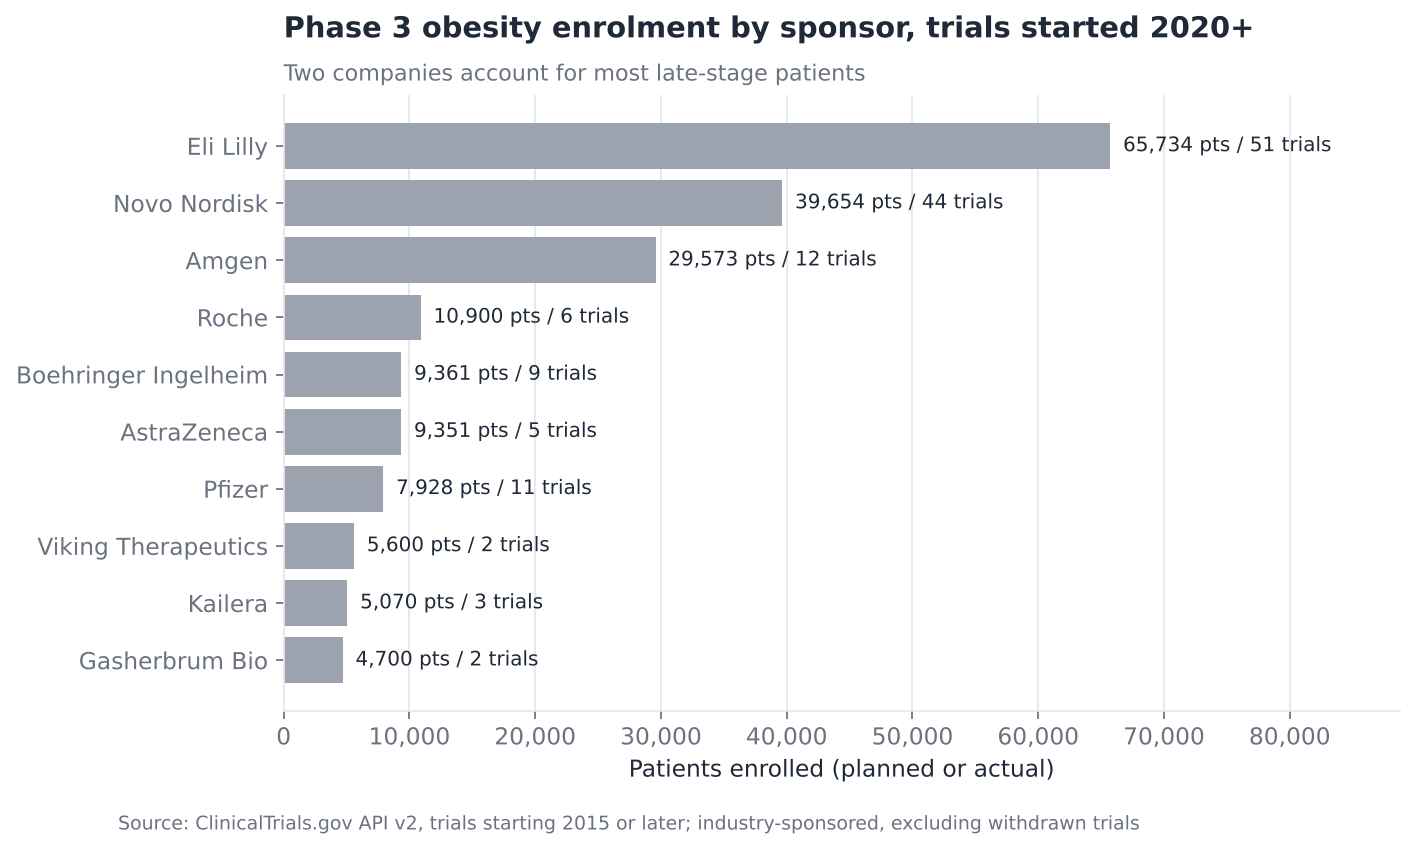

Top two sponsors hold 48% of Phase 3 patients


,trials,patients
sponsor,,
Eli Lilly,51,65734
Novo Nordisk,44,39654
Amgen,12,29573
Roche,6,10900
Boehringer Ingelheim,9,9361
AstraZeneca,5,9351
Pfizer,11,7928
Viking Therapeutics,2,5600
Kailera,3,5070


In [6]:
ph3 = trials[(trials["sponsor_class"] == "INDUSTRY") & (trials["phase"] == "PHASE3") & (trials["start_year"] >= 2020)
             & ~trials["overall_status"].isin(["WITHDRAWN"])]
def short(name: str) -> str:
    name = name.split(",")[0]
    for x in [" and Company", " A/S", " Inc.", " Co. Ltd.", " Pharmaceuticals", " (Suzhou)", " (China)", " Limited", " Co.", " GmbH"]:
        name = name.replace(x, "")
    return name.replace("Hoffmann-La Roche", "Roche").strip()


ph3 = ph3.assign(sponsor=ph3["sponsor"].map(short))
spon = (ph3.groupby("sponsor").agg(trials=("nct_id", "count"), patients=("enrollment", "sum"))
           .sort_values("patients", ascending=False))
top = spon.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
colors = [style.ACCENT if s in ("Eli Lilly and Company", "Novo Nordisk A/S") else style.NEUTRAL for s in top.index]
ax.barh(top.index, top["patients"], color=colors)
for y, (p, t) in enumerate(zip(top["patients"], top["trials"])):
    ax.text(p, y, f"  {p:,.0f} pts / {t} trials", va="center", fontsize=9, color=style.INK)
ax.set_title("Phase 3 obesity enrolment by sponsor, trials started 2020+")
style.subtitle(ax, "Two companies account for most late-stage patients")
ax.set_xlabel("Patients enrolled (planned or actual)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top["patients"].max() * 1.35)
style.source(fig, SRC + "; industry-sponsored, excluding withdrawn trials")
style.save(fig, FIG / "02_phase3_enrolment_by_sponsor.png")
lead_share = spon["patients"].head(2).sum() / spon["patients"].sum()
print(f"Top two sponsors hold {lead_share:.0%} of Phase 3 patients")
spon.head(12)

## 5. Readout calendar: Phase 3 primary completions still ahead

Each dot is an industry Phase 3 trial with US sites, for a molecule still in
development. The dot sits at the trial's primary completion date (actual dates
for finished trials, sponsor estimates for ongoing ones).

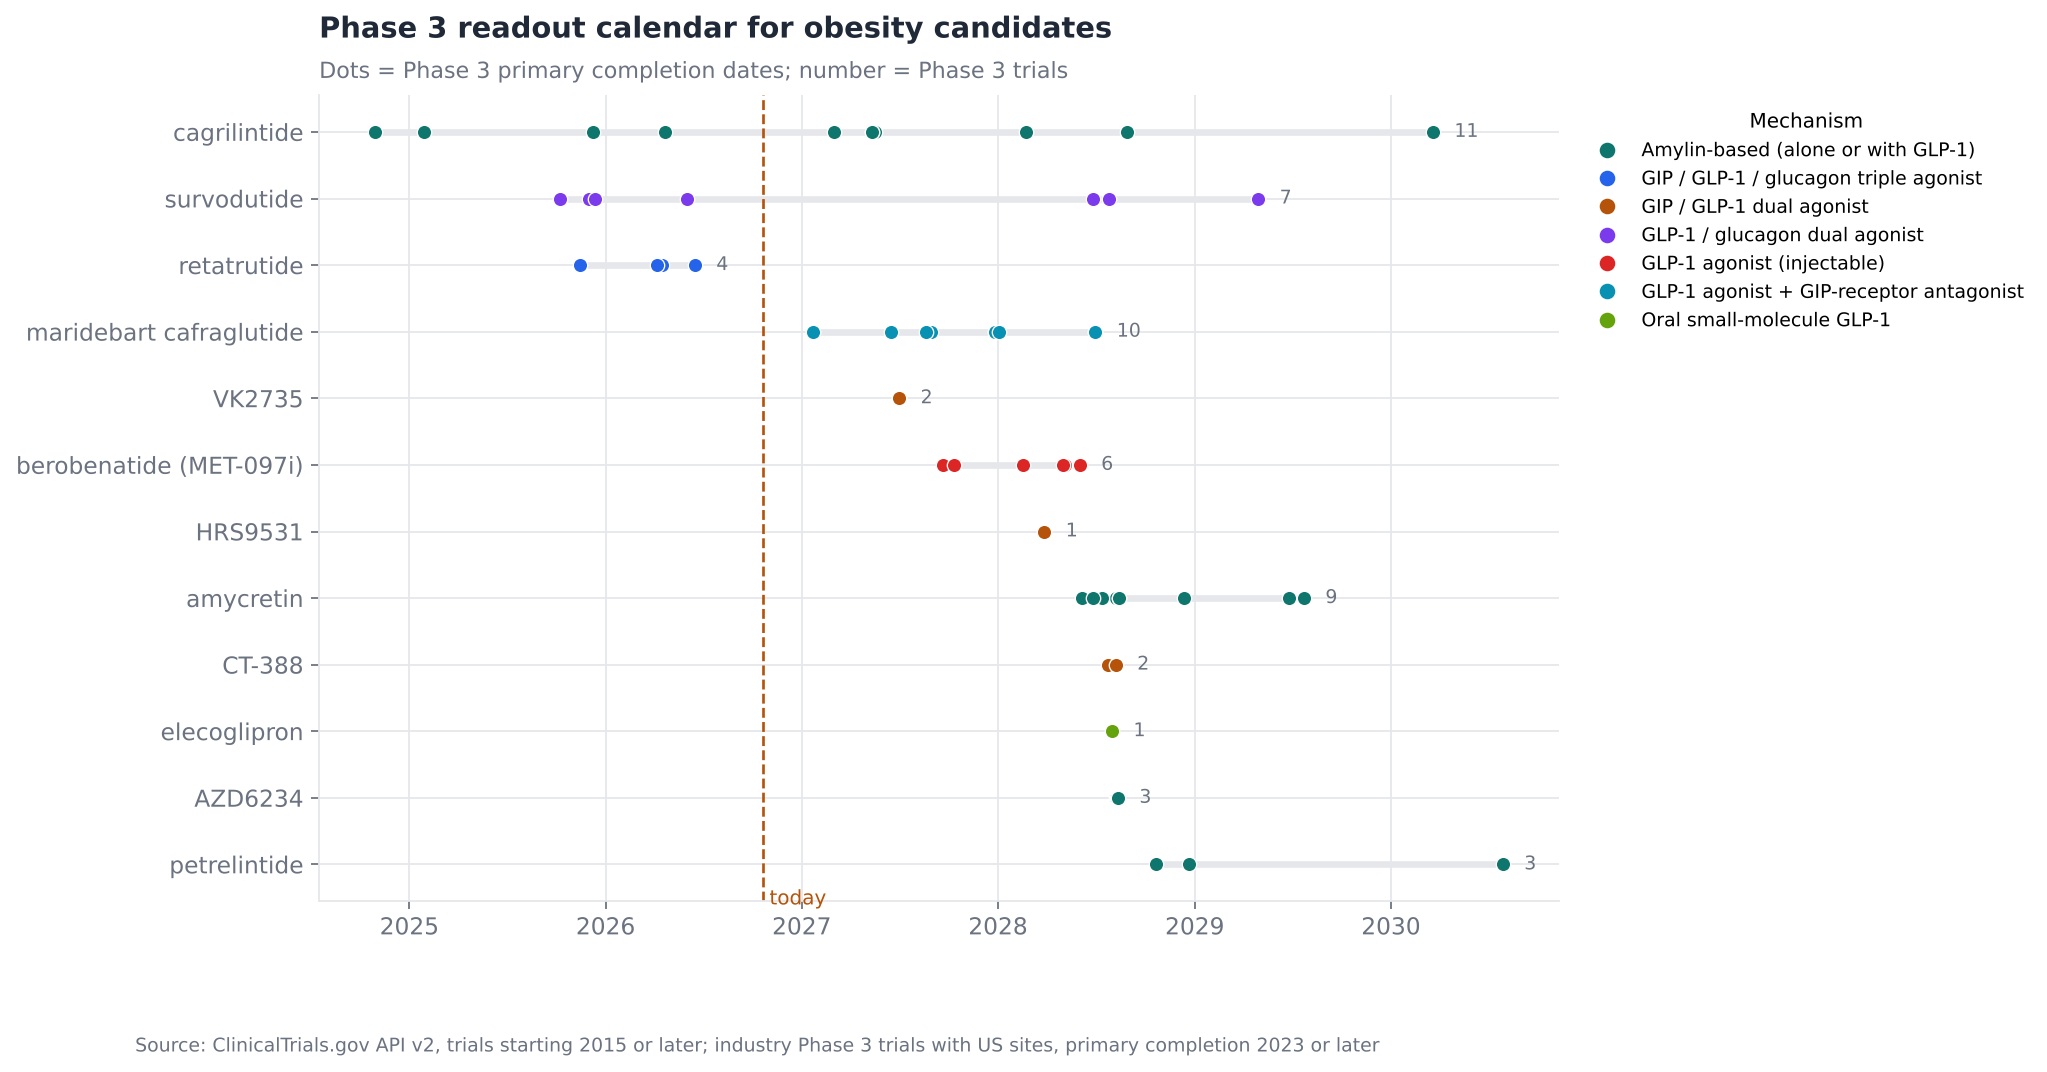

In [7]:
today = pd.Timestamp.today().normalize()
us_dev = set(dev.loc[dev["us_max_phase"] == 3, "molecule"])
cal = live[(live["phase_rank"] == 3) & live["us_site"] & live["molecule"].isin(us_dev) & live["pcd"].notna()
           & (live["pcd"] >= pd.Timestamp("2023-01-01"))].copy()
mol_order = cal.groupby("molecule")["pcd"].min().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(10, max(3.5, 0.42 * len(mol_order) + 1.5)))
mechs = sorted(cal["mechanism"].unique())
cmap = {mk: style.PALETTE[i % len(style.PALETTE)] for i, mk in enumerate(mechs)}
for y, mol in enumerate(mol_order):
    d = cal[cal["molecule"] == mol]
    ax.plot([d["pcd"].min(), d["pcd"].max()], [y, y], color=style.GRID, lw=3, zorder=1)
    ax.scatter(d["pcd"], [y] * len(d), color=cmap[d["mechanism"].iloc[0]], s=42, zorder=2,
               edgecolor="white", linewidth=0.6)
    ax.text(d["pcd"].max() + pd.Timedelta(days=40), y, f"{len(d)}", va="center", fontsize=8.5, color=style.MUTED)
ax.axvline(today, color=style.ACCENT_2, lw=1.2, ls="--")
ax.text(today, len(mol_order) - 0.4, " today", color=style.ACCENT_2, fontsize=9)
ax.set_yticks(range(len(mol_order)))
ax.set_yticklabels(mol_order)
ax.invert_yaxis()
ax.set_title("Phase 3 readout calendar for obesity candidates")
style.subtitle(ax, "Dots = Phase 3 primary completion dates; number = Phase 3 trials")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in cmap.items()]
ax.legend(handles=handles, loc="upper left", fontsize=8.5, bbox_to_anchor=(1.01, 1.0), title="Mechanism", title_fontsize=9)
style.source(fig, SRC + "; industry Phase 3 trials with US sites, primary completion 2023 or later")
style.save(fig, FIG / "03_phase3_readout_calendar.png")

## 6. How many new entrants should we expect, and when?

Historical success rates for metabolic drugs (BIO, Biomedtracker and Amplion,
*Clinical Development Success Rates 2006–2015*):

| Transition | Metabolic | All indications |
|---|---|---|
| Phase 1 → 2 | 61.1% | 63.2% |
| Phase 2 → 3 | 45.2% | 30.7% |
| Phase 3 → filing | 71.4% | 58.1% |
| Filing → approval | 77.8% | 85.3% |

These rates come from all metabolic drugs. Incretin-based drugs act on a
validated mechanism and have succeeded far more often, so the base case uses
the metabolic rates and an upside case raises Phase 3 → filing to 90%.

Timing assumption: filing about 6 months after the last Phase 3 primary
completion, then a 10-month standard FDA review (about 16 months in total).
Phase 2 assets are assumed to need about 3.5 more years before approval.
The question is about US competitors, so each molecule is staged by its most
advanced trial **with US sites**, and timed off those trials' completion dates.
A molecule in Phase 3 in China but only Phase 2 in the US counts as Phase 2.

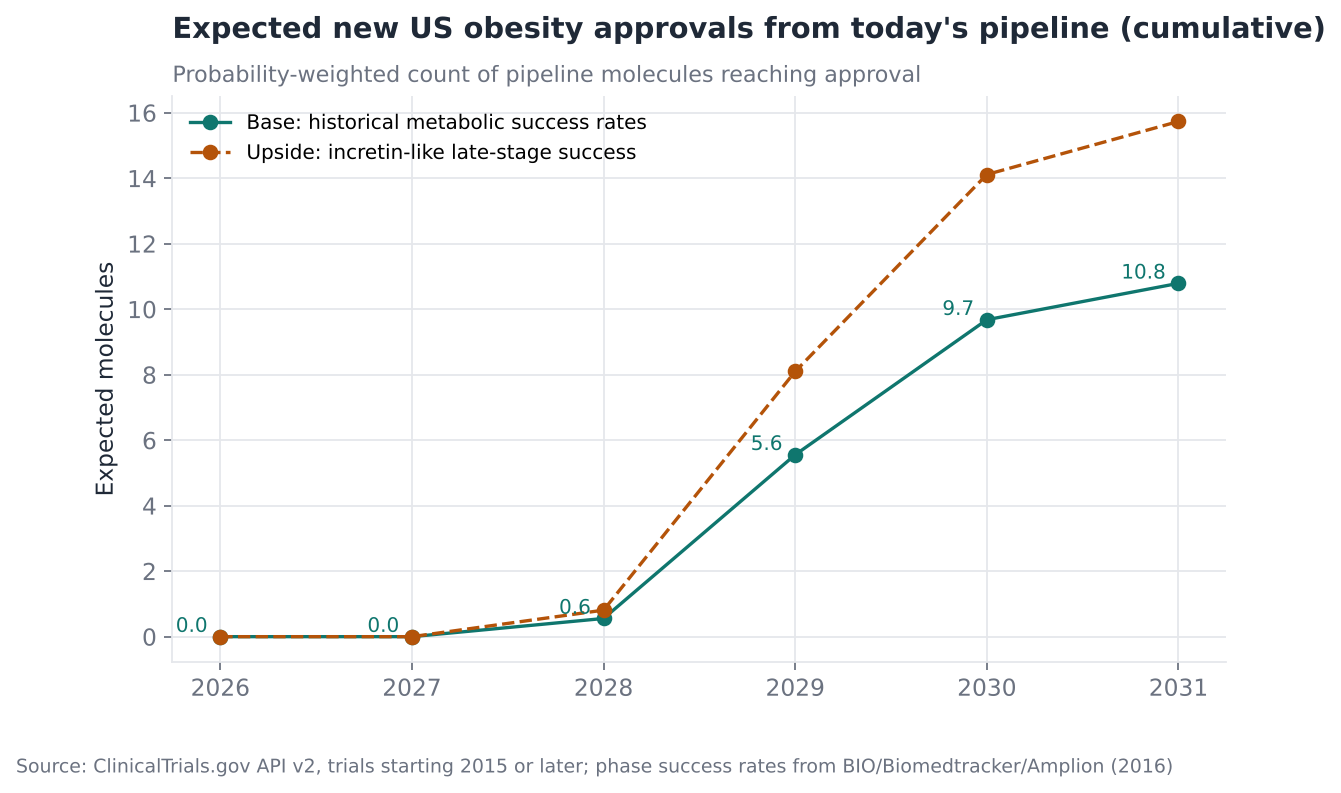

,molecule,mol_sponsor,mechanism,us_max_phase,ph3_trials,ph3_enrolment,last_us_ph3_pcd,p_base,p_upside,exp_approval
10,VK2735,Viking Therapeutics,GIP / GLP-1 dual agonist,3.0,4,6720,2027-07-01,0.555492,0.81000,2028.0
30,maridebart cafraglutide,Amgen,GLP-1 agonist + GIP-receptor antagonist,3.0,12,29573,2028-06-30,0.555492,0.81000,2029.0
40,retatrutide,Eli Lilly,GIP / GLP-1 / glucagon triple agonist,3.0,10,18757,2028-01-24,0.555492,0.81000,2029.0
25,eloralintide,Eli Lilly,Amylin-based (alone or with GLP-1),3.0,7,8730,2028-02-10,0.555492,0.81000,2029.0
14,berobenatide (MET-097i),Pfizer (from Metsera),GLP-1 agonist (injectable),3.0,10,7895,2028-06-01,0.555492,0.81000,2029.0
6,HRS9531,Hengrui / Kailera,GIP / GLP-1 dual agonist,3.0,8,7164,2028-03-27,0.555492,0.81000,2029.0
24,elecoglipron,AstraZeneca,Oral small-molecule GLP-1,3.0,2,4851,2028-07-31,0.555492,0.81000,2029.0
11,aleniglipron,Structure Therapeutics,Oral small-molecule GLP-1,3.0,2,4700,2028-07-17,0.555492,0.81000,2029.0
0,AZD6234,AstraZeneca,Amylin-based (alone or with GLP-1),3.0,3,4500,2028-08-11,0.555492,0.81000,2029.0
3,CT-388,Roche,GIP / GLP-1 dual agonist,3.0,3,3900,2028-08-07,0.555492,0.81000,2029.0


In [8]:
P = {"base": {1: .611 * .452 * .714 * .778, 2: .452 * .714 * .778, 3: .714 * .778},
     "upside": {1: .611 * .452 * .90 * .90, 2: .452 * .90 * .90, 3: .90 * .90}}

cand = pipe[(pipe["status"] == "In development") & (pipe["us_max_phase"].between(2, 3))].copy()
cand["p_base"] = cand["us_max_phase"].map(P["base"])
cand["p_upside"] = cand["us_max_phase"].map(P["upside"])
lag3 = pd.DateOffset(months=16)
cand["exp_approval"] = np.where(
    cand["us_max_phase"] == 3,
    (cand["last_us_ph3_pcd"] + lag3).dt.year,
    today.year + 4)
cand["exp_approval"] = cand["exp_approval"].clip(lower=today.year)
cand = cand.sort_values(["us_max_phase", "exp_approval", "ph3_enrolment"], ascending=[False, True, False])
cand.to_csv(TAB / "launch_probability.csv", index=False)

years = range(today.year, today.year + 6)
exp = pd.DataFrame({
    "year": years,
    "base": [cand.loc[cand["exp_approval"] <= y, "p_base"].sum() for y in years],
    "upside": [cand.loc[cand["exp_approval"] <= y, "p_upside"].sum() for y in years],
})
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(exp["year"], exp["base"], marker="o", color=style.ACCENT, label="Base: historical metabolic success rates")
ax.plot(exp["year"], exp["upside"], marker="o", color=style.ACCENT_2, ls="--", label="Upside: incretin-like late-stage success")
for x, b in zip(exp["year"], exp["base"]):
    ax.text(x, b, f"{b:.1f}  ", ha="right", va="bottom", fontsize=9, color=style.ACCENT)
ax.set_title("Expected new US obesity approvals from today's pipeline (cumulative)")
style.subtitle(ax, "Probability-weighted count of pipeline molecules reaching approval")
ax.set_ylabel("Expected molecules")
ax.set_xticks(list(years))
ax.legend(loc="upper left", fontsize=9)
style.source(fig, SRC + "; phase success rates from BIO/Biomedtracker/Amplion (2016)")
style.save(fig, FIG / "04_expected_new_entrants.png")
cand[["molecule", "mol_sponsor", "mechanism", "us_max_phase", "ph3_trials", "ph3_enrolment",
      "last_us_ph3_pcd", "p_base", "p_upside", "exp_approval"]].head(30)

## 7. Where the trials run: the rise of China-based development

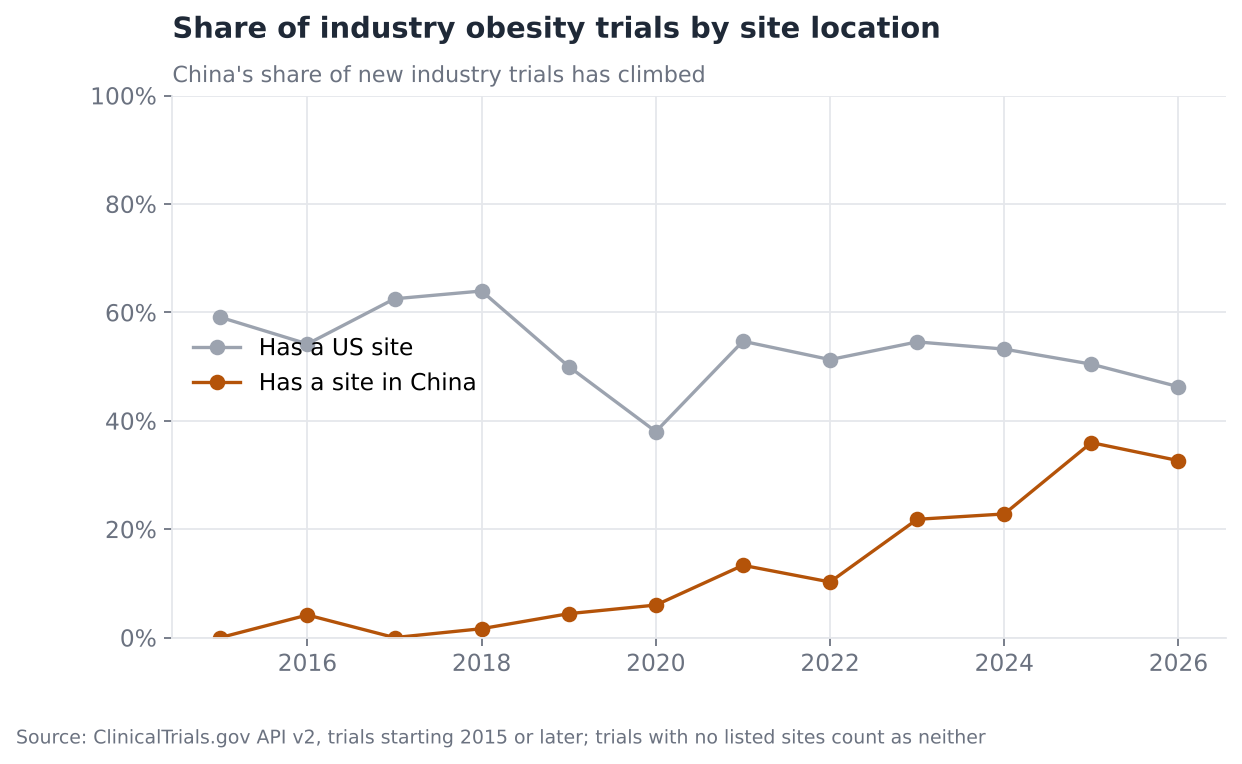

,china,us
start_year,,
2015.0,0.00,0.59
2016.0,0.04,0.54
2017.0,0.00,0.62
2018.0,0.02,0.64
2019.0,0.04,0.50
2020.0,0.06,0.38
2021.0,0.13,0.55
2022.0,0.10,0.51
2023.0,0.22,0.55


In [9]:
ind_tr = trials[(trials["sponsor_class"] == "INDUSTRY") & trials["start_year"].between(2015, today.year)].copy()
ind_tr["china"] = ind_tr["countries"].fillna("").str.contains("China")
ind_tr["us"] = ind_tr["countries"].fillna("").str.contains("United States")
geo = ind_tr.groupby("start_year")[["china", "us"]].mean()

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(geo.index, geo["us"], marker="o", color=style.NEUTRAL, label="Has a US site")
ax.plot(geo.index, geo["china"], marker="o", color=style.ACCENT_2, label="Has a site in China")
ax.set_title("Share of industry obesity trials by site location")
style.subtitle(ax, "China's share of new industry trials has climbed")
style.pct(ax)
ax.set_ylim(0, 1)
ax.legend(loc="center left")
style.source(fig, SRC + "; trials with no listed sites count as neither")
style.save(fig, FIG / "05_trial_geography.png")
geo.round(2)

Late-stage programmes with Phase 3 running outside the US but not yet in the US
(mostly China-first). These are the assets US companies have been licensing.

In [10]:
china_first = dev[(dev["max_phase"] == 3) & (dev["us_max_phase"] < 3)][["molecule", "mol_sponsor", "mechanism", "us_max_phase", "ph3_trials", "ph3_enrolment"]]
china_first.to_csv(TAB / "china_first_programmes.csv", index=False)
china_first

,molecule,mol_sponsor,mechanism,us_max_phase,ph3_trials,ph3_enrolment
31,mazdutide,Innovent / Eli Lilly,GLP-1 / glucagon dual agonist,2.0,7,2676
16,bofanglutide,Gan & Lee,GLP-1 agonist (injectable),2.0,6,2182
22,ecnoglutide,Sciwind Biosciences,GLP-1 agonist (injectable),2.0,5,1496
5,HRS-7535,Hengrui / Kailera,Oral small-molecule GLP-1,0.0,2,1204
2,BGM0504,BrightGene,GIP / GLP-1 dual agonist,1.0,2,1024
9,UBT251,United Laboratories / Novo Nordisk,GIP / GLP-1 / glucagon triple agonist,2.0,3,900
46,zovaglutide,"Beijing QL Biopharmaceutical Co.,Ltd",GLP-1 agonist (injectable),0.0,1,755
33,olatorepatide,Regeneron / Hansoh,GIP / GLP-1 dual agonist,2.0,1,604


## 8. Summary numbers used in the README

In [11]:
summary = {
    "trials_total": len(trials),
    "industry_trials": int((trials["sponsor_class"] == "INDUSTRY").sum()),
    "named_molecules": int(pipe["molecule"].nunique()),
    "in_development": int(len(dev)),
    "in_development_ph3": int((dev["max_phase"] == 3).sum()),
    "in_development_ph3_us": int((dev["us_max_phase"] == 3).sum()),
    "in_development_ph2_us": int((dev["us_max_phase"] == 2).sum()),
    "china_first_ph3": int(len(china_first)),
    "china_site_share_2015": float(geo.loc[2015, "china"]) if 2015 in geo.index else None,
    "china_site_share_2025": float(geo.loc[2025, "china"]) if 2025 in geo.index else None,
    "top2_ph3_patient_share": round(float(lead_share), 3),
    "expected_new_by_2030_base": round(float(exp.loc[exp["year"] == 2030, "base"].iloc[0]), 1) if 2030 in exp["year"].values else None,
    "expected_new_by_2030_upside": round(float(exp.loc[exp["year"] == 2030, "upside"].iloc[0]), 1) if 2030 in exp["year"].values else None,
}
pd.Series(summary).to_json(TAB / "summary.json", indent=1)
pd.Series(summary)

trials_total                   8309.000000
industry_trials                1300.000000
named_molecules                  47.000000
in_development                   31.000000
in_development_ph3               22.000000
in_development_ph3_us            14.000000
in_development_ph2_us            12.000000
china_first_ph3                   8.000000
china_site_share_2015             0.000000
china_site_share_2025             0.359649
top2_ph3_patient_share            0.483000
expected_new_by_2030_base         9.700000
expected_new_by_2030_upside      14.100000
dtype: float64